# เตรียมข้อมูลสำหรับโมเดล: Impute + Missing Flag vs Impute Only

เป้าหมาย: สร้างตารางที่ไม่มีค่าว่างใน **feature** สำหรับโมเดลทำนาย
1. **ชื่อวิทยาศาสตร์ (`sci_name`)** ที่ขาด: ระดับตัวอย่าง
2. **ยุค (`period`)** ที่ขาด: ระดับแหล่ง (และระดับตัวอย่างผ่านแหล่งที่เชื่อม)

ทำ 2 แบบไว้เปรียบเทียบ
- **Impute + Missing Flag**: แทนค่าที่ขาด และเพิ่มคอลัมน์ flag บอกว่าแถวไหนเดิมขาด (โมเดลเรียนรู้จากการขาดได้)
- **Impute Only**: แทนค่าที่ขาดอย่างเดียว ไม่มี flag

### กติกาการแทนค่า

| คอลัมน์ | แทนด้วย | flag (เฉพาะแบบ Impute + Flag) | เหตุผล |
|---|---|---|---|
| `FORMATION` | `'Unknown'` | `formation_missing` | ชั้นหินสำคัญ และการขาดหายอาจมีความหมาย |
| `GEO_GROUP` | `'Unknown'` | `geo_group_missing` | กลุ่มหินสัมพันธ์กับยุค และรูปแบบการขาดอาจสำคัญ |
| `LOCALITY` | `''` (ข้อความว่าง) | `has_locality` | ใช้ร่วมกับพิกัด การมี/ไม่มีอาจสัมพันธ์กับการค้นพบ |
| `UTM_E`, `UTM_N`, `geometry_x`, `geometry_y` | ค่าเฉลี่ยของจังหวัด | `coord_imputed`, `coord_impute_level` | ข้อมูลเกือบครบ ค่าเฉลี่ยตามพื้นที่สมเหตุสมผล |
| `SCI_NAME` (target) | **คงค่า null** | – | เป็น target แทนค่าแล้วโมเดลจะสับสน |

### ส่วนที่เพิ่มจากกติกา (อธิบายไว้ตรงจุดที่ใช้)
- **พิกัดของจังหวัดที่ไม่มีแหล่ง**: ตัวอย่างที่ไม่มีพิกัดทั้งหมดอยู่ในจังหวัดที่**ไม่มีแหล่งใน DB** (เช่น สมุทรสาคร) จึงหาค่าเฉลี่ยจากแหล่งไม่ได้
  ใช้ลำดับสำรอง: ค่าเฉลี่ยพิกัดแหล่งในจังหวัด → **จุดกึ่งกลางจังหวัด** (ขอบเขตจังหวัดของ ทธ. `data/dmr_admin/provinces.geojson`) → ค่าเฉลี่ยทั้งประเทศ (เมื่อไม่รู้จังหวัด)
- **ยุค (target) คงค่า null** เหมือน `SCI_NAME` ใช้เฉพาะ `PERIODFROM` ที่ ทธ. บันทึกไว้ ไม่ใช้ค่าที่เติมใน notebook 03–05 เป็น target
  (เก็บไว้เป็นคอลัมน์อ้างอิง `ref_*` สำหรับเทียบ **ห้ามใช้เป็น feature**)
- **feature อื่นที่มีค่าว่าง** (`com_name`, `f_type`, `f_part`, `dis_name`, `province`, `district`, `tambon`): ใช้กติกาเดียวกับข้อมูลธรณี
  คือ `'Unknown'` + `<คอลัมน์>_missing` เพื่อให้ตาราง feature ไม่มีค่าว่างเหลือ

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, KFold, RepeatedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

DATA = Path("../data")
OUT = DATA / "processed"
MODEL_DIR = OUT / "model"
MODEL_DIR.mkdir(exist_ok=True)

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 60, "display.max_colwidth", 50, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
VERSION_COLOR = {"impute_flag": "#eb6834", "impute_only": "#2a78d6"}
VERSION_NAME = {"impute_flag": "Impute + Missing Flag", "impute_only": "Impute Only"}
ID_DTYPES = {"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str, "site_OBJECTID": "Int64"}

## 1. โหลดข้อมูลและสร้างตารางตั้งต้น (ยังไม่แทนค่า)

ต้องรัน notebook 02–05 ก่อน
- **ตารางแหล่ง** (518 แถว): คุณสมบัติแหล่งจากไฟล์ ทธ. ต้นฉบับ + จำนวนตัวอย่างที่เชื่อมได้ (02) + target ยุค
- **ตารางตัวอย่าง** (8,521 แถว): ข้อมูลทะเบียน + คุณสมบัติของแหล่งที่เชื่อม (02) + target ชื่อวิทยาศาสตร์และยุค

In [2]:
def clean_th(s):
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFC", s).replace("ํา", "ำ")
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"^[ัิ-ฺ็-๎]+", "", s) or None


ORDER = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
         "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
RANK = {p: i for i, p in enumerate(ORDER)}
PERIOD_TH = {
    "Cambrian": r"แคมเบรียน", "Ordovician": r"ออร์โด", "Silurian": r"ไซลูเรียน", "Devonian": r"ดีโวเนียน",
    "Carboniferous": r"คาร์บอนิเฟอรัส", "Permian": r"เพอร์เมียน", "Triassic": r"ไทรแอส", "Jurassic": r"จู(?:แร|รา)ส",
    "Cretaceous": r"ครีเท", "Tertiary": r"เทอร์เชียรี|นีโอจีน|พาลีโอจีน|ไมโอซีน|ไพลโอซีน|โอลิโกซีน|อีโอซีน",
    "Quaternary": r"ควอเทอร์นารี|ไพลสโตซีน|โฮโลซีน",
}


def parse_period_th(text):
    if not isinstance(text, str):
        return (None, None)
    found = sorted((p for p, pat in PERIOD_TH.items() if re.search(pat, text)), key=RANK.get)
    return (found[0], found[-1]) if found else (None, None)


# ---- ตารางแหล่ง ----
raw = gpd.read_file(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")
for c in raw.columns:
    if c != "geometry" and (pd.api.types.is_string_dtype(raw[c]) or raw[c].dtype == object):
        raw[c] = raw[c].map(clean_th).replace({"<Null>": None})
raw["OBJECTID"] = raw.OBJECTID.astype(int)
GR = {"FOS_GR_1": "gr_vertebrate", "FOS_GR_2": "gr_invertebrate", "FOS_GR_3": "gr_plant", "FOS_GR_4": "gr_trace", "FOS_GR_5": "gr_other"}

site_base = pd.DataFrame({
    "OBJECTID": raw.OBJECTID, "SITE_CODE": raw.SITE_CODE, "NAME_TH": raw.NAME_TH,
    "PROVINCE": raw.PROVINCE, "DISTRICT": raw.DISTRICT, "TAMBON": raw.TAMBON,
    "FORMATION": raw.FORMATION, "GEO_GROUP": raw.GEO_GROUP, "LOCALITY": raw.LOCALITY,
    "UTM_E": raw.UTM_E.astype(float), "UTM_N": raw.UTM_N.astype(float),
    "geometry_x": raw.geometry.x, "geometry_y": raw.geometry.y,
    "IMPORTA_TH": raw.IMPORTA_TH.str.rstrip("*"),
    **{new: (raw[col].notna() & raw[col].ne("N")).astype(int) for col, new in GR.items()},
})
counts = gpd.read_file(OUT / "sites_with_specimen_counts.geojson")[["OBJECTID", "n_specimens"]]
site_base = site_base.merge(counts.rename(columns={"n_specimens": "n_specimens_linked"}), on="OBJECTID", how="left")
site_base[["target_period", "target_period_young"]] = raw.PERIODFROM.map(parse_period_th).tolist()
final = pd.read_csv(OUT / "sites_period_final.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
site_base = site_base.merge(final[["OBJECTID", "PERIODFROM", "final_old", "final_source", "final_confidence"]].rename(columns={
    "PERIODFROM": "ref_PERIODFROM_raw", "final_old": "ref_period_final", "final_source": "ref_period_final_source",
    "final_confidence": "ref_period_final_confidence"}), on="OBJECTID", how="left")

# ---- ตารางตัวอย่าง ----
spec_raw = pd.read_csv(OUT / "fossil_list_final.csv", dtype=ID_DTYPES, encoding="utf-8-sig", low_memory=False)
site_attr = site_base.set_index("OBJECTID")
sid = spec_raw.site_OBJECTID
spec_base = pd.DataFrame({
    "fossil_id": spec_raw.fossil_id,
    "com_name": spec_raw.com_name, "f_type": spec_raw.f_type, "f_group": spec_raw.f_group, "f_part": spec_raw.f_part,
    "dis_name": spec_raw.dis_name, "province": spec_raw.province, "district": spec_raw.district, "tambon": spec_raw.tambon,
    "match_level": spec_raw.match_level, "merge_confidence": spec_raw.confidence, "site_OBJECTID": sid,
    "FORMATION": spec_raw.site_FORMATION, "GEO_GROUP": spec_raw.site_GEO_GROUP, "LOCALITY": spec_raw.site_LOCALITY,
    "UTM_E": sid.map(site_attr.UTM_E), "UTM_N": sid.map(site_attr.UTM_N),
    "geometry_x": spec_raw.site_longitude, "geometry_y": spec_raw.site_latitude,
})

# target ชื่อวิทยาศาสตร์: 'N/A (Dinosaur)' ไม่ใช่ชื่อ -> null, เก็บกลุ่มกว้างไว้เป็นคอลัมน์อ้างอิง
is_na_group = spec_raw.sci_name.fillna("").str.match(r"^N/A\s*\(")
spec_base["target_sci_name"] = spec_raw.sci_name.mask(is_na_group)
spec_base["target_genus"] = spec_raw.genus.mask(is_na_group)
spec_base["target_period"] = sid.map(site_attr.target_period)
spec_base["ref_broad_taxon"] = spec_raw.sci_name.str.extract(r"^N/A\s*\((.*)\)")[0]
spec_base["ref_period_final"] = spec_raw.site_final_old
spec_base["ref_period_final_confidence"] = spec_raw.site_final_confidence

print(f"ตารางแหล่ง {site_base.shape} | ตารางตัวอย่าง {spec_base.shape}")
print(f"target ยุค (แหล่ง): มี {site_base.target_period.notna().sum()} ว่าง {site_base.target_period.isna().sum()}")
print(f"target ชื่อวิทยาศาสตร์ (ตัวอย่าง): มี {spec_base.target_sci_name.notna().sum():,} ว่าง {spec_base.target_sci_name.isna().sum():,}")

ตารางแหล่ง (518, 26) | ตารางตัวอย่าง (8521, 25)
target ยุค (แหล่ง): มี 166 ว่าง 352
target ชื่อวิทยาศาสตร์ (ตัวอย่าง): มี 4,714 ว่าง 3,807


In [3]:
def missing_report(df, name):
    m = df.isna().sum()
    m = m[m > 0]
    return pd.DataFrame({"table": name, "missing": m, "missing_%": (m / len(df) * 100).round(1)})


pd.concat([missing_report(site_base, "แหล่ง"), missing_report(spec_base, "ตัวอย่าง")])

,table,missing,missing_%
FORMATION,แหล่ง,346,66.8
GEO_GROUP,แหล่ง,341,65.8
LOCALITY,แหล่ง,254,49.0
target_period,แหล่ง,352,68.0
target_period_young,แหล่ง,352,68.0
ref_PERIODFROM_raw,แหล่ง,352,68.0
ref_period_final,แหล่ง,129,24.9
ref_period_final_confidence,แหล่ง,129,24.9
com_name,ตัวอย่าง,50,0.6
f_type,ตัวอย่าง,2,0.0


ค่าที่ขาดในตารางตั้งต้น: target (`target_*`) และคอลัมน์อ้างอิง (`ref_*`) **ต้องคงค่า null ไว้**
ที่เหลือเป็น feature ที่ต้องแทนค่า

### พิกัดที่ขาดอยู่จังหวัดไหน

In [4]:
no_xy = spec_base.geometry_x.isna()
site_provs = set(site_base.PROVINCE)
where = np.select([spec_base.province.isna(), spec_base.province.isin(site_provs)], ["ไม่รู้จังหวัด", "จังหวัดที่มีแหล่ง"], "จังหวัดที่ไม่มีแหล่งใน DB")
print(f"ตัวอย่างที่ไม่มีพิกัด: {no_xy.sum()} ชิ้น")
display(pd.Series(where[no_xy]).value_counts().rename("ตัวอย่าง").to_frame())
spec_base.loc[no_xy & ~spec_base.province.isin(site_provs) & spec_base.province.notna(), "province"].value_counts().head(8).to_frame("ตัวอย่าง")

ตัวอย่างที่ไม่มีพิกัด: 668 ชิ้น


,ตัวอย่าง
จังหวัดที่ไม่มีแหล่งใน DB,477
ไม่รู้จังหวัด,191


,ตัวอย่าง
province,
สมุทรสาคร,247
จันทบุรี,59
ประจวบคีรีขันธ์,37
สุพรรณบุรี,30
ลำพูน,24
เชียงใหม่,24
แม่ฮ่องสอน,14
หนองคาย,13


ไม่มีตัวอย่างไหนที่ขาดพิกัดแล้วอยู่ในจังหวัดที่มีแหล่งเลย จึงต้องมีค่าสำรองเป็น**จุดกึ่งกลางจังหวัด** จากขอบเขตจังหวัดของ ทธ.
คำนวณจุดกึ่งกลางในระบบพิกัด UTM 47N (EPSG:32647) ซึ่งเป็นระบบเดียวกับ `UTM_E`/`UTM_N` ของแหล่ง แล้วแปลงเป็นละติจูด/ลองจิจูด

## 2. ฟังก์ชันแทนค่า

แยกเป็น `fit_impute` (คำนวณค่าสถิติจากข้อมูล train) กับ `impute` (นำไปใช้)
เวลาทำ cross-validation ให้ `fit` บน train fold แล้ว `impute` ทั้ง train และ test จะได้ไม่รั่วข้อมูล

In [5]:
COORDS = ["UTM_E", "UTM_N", "geometry_x", "geometry_y"]
GEO_FLAGS = {"FORMATION": "formation_missing", "GEO_GROUP": "geo_group_missing"}
EXTRA_CAT = {"site": [], "spec": ["com_name", "f_type", "f_part", "dis_name", "district", "tambon"]}

prov = gpd.read_file(DATA / "dmr_admin" / "provinces.geojson")[["prov_nam_t", "geometry"]].to_crs(32647)
cent = prov.geometry.centroid
cent_ll = gpd.GeoSeries(cent, crs=32647).to_crs(4326)
PROV_CENTROID = pd.DataFrame({"UTM_E": cent.x.values, "UTM_N": cent.y.values, "geometry_x": cent_ll.x.values,
                              "geometry_y": cent_ll.y.values}, index=prov.prov_nam_t.str.strip().values)


def fit_impute(sites_train):
    # ค่าสถิติจากพิกัดของแหล่ง (ระดับแหล่ง ไม่ถ่วงด้วยจำนวนตัวอย่าง: แหล่งใหญ่ไม่ดึงค่าเฉลี่ย)
    return {"prov_mean": sites_train.groupby("PROVINCE")[COORDS].mean(),
            "prov_centroid": PROV_CENTROID,
            "global_mean": sites_train[COORDS].mean()}


def impute(df, params, add_flags, province_col, extra_cat=()):
    out = df.copy()
    # 1) ข้อมูลธรณี: 'Unknown' (+ flag)
    for col, flag in GEO_FLAGS.items():
        if add_flags:
            out[flag] = out[col].isna().astype(int)
        out[col] = out[col].fillna("Unknown")
    # 2) สถานที่: '' (+ has_locality)
    if add_flags:
        out["has_locality"] = out.LOCALITY.notna().astype(int)
    out["LOCALITY"] = out.LOCALITY.fillna("")
    # 3) พิกัด: ค่าเฉลี่ยจังหวัด -> จุดกึ่งกลางจังหวัด -> ค่าเฉลี่ยทั้งประเทศ
    missing = out[COORDS].isna().any(axis=1)
    level = pd.Series(np.where(missing, None, "observed"), index=out.index, dtype=object)
    for source, table in [("province_mean", params["prov_mean"]), ("province_centroid", params["prov_centroid"])]:
        need = out[COORDS].isna().any(axis=1) & out[province_col].isin(table.index)
        if need.any():
            vals = table.loc[out.loc[need, province_col], COORDS].to_numpy()
            out.loc[need, COORDS] = out.loc[need, COORDS].fillna(pd.DataFrame(vals, index=out.index[need], columns=COORDS))
            level[need] = source
    need = out[COORDS].isna().any(axis=1)
    out.loc[need, COORDS] = out.loc[need, COORDS].fillna(params["global_mean"])
    level[need] = "global_mean"
    if add_flags:
        out["coord_imputed"] = missing.astype(int)
        out["coord_impute_level"] = level
    # 4) feature หมวดหมู่อื่น: 'Unknown' (+ <col>_missing) | จังหวัดทำหลังพิกัด เพราะพิกัดใช้ชื่อจังหวัดจริง
    for col in list(extra_cat) + ([province_col] if out[province_col].isna().any() else []):
        if add_flags:
            out[f"{col}_missing"] = out[col].isna().astype(int)
        out[col] = out[col].fillna("Unknown")
    # 5) target / ref: ไม่แตะ (คง null)
    return out


params = fit_impute(site_base)
print("ค่าเฉลี่ยพิกัดรายจังหวัด:", len(params["prov_mean"]), "จังหวัด | จุดกึ่งกลางจังหวัด:", len(PROV_CENTROID), "จังหวัด")

ค่าเฉลี่ยพิกัดรายจังหวัด: 39 จังหวัด | จุดกึ่งกลางจังหวัด: 77 จังหวัด


## 3. สร้างตาราง 4 ชุด (แหล่ง/ตัวอย่าง × มี flag/ไม่มี flag)

In [6]:
tables = {}
for version, flags in [("impute_flag", True), ("impute_only", False)]:
    tables[("site", version)] = impute(site_base, params, flags, "PROVINCE", EXTRA_CAT["site"])
    tables[("spec", version)] = impute(spec_base, params, flags, "province", EXTRA_CAT["spec"])

TARGETS = {"site": ["target_period", "target_period_young"], "spec": ["target_sci_name", "target_genus", "target_period"]}
REFS = {"site": [c for c in site_base.columns if c.startswith("ref_")], "spec": [c for c in spec_base.columns if c.startswith("ref_")]}
IDS = {"site": ["OBJECTID", "SITE_CODE", "NAME_TH"], "spec": ["fossil_id", "site_OBJECTID"]}

rows = []
for (level, version), t in tables.items():
    feats = [c for c in t.columns if c not in TARGETS[level] + REFS[level] + IDS[level]]
    flags_ = [c for c in t.columns if c.endswith("_missing") or c in ("has_locality", "coord_imputed", "coord_impute_level")]
    rows.append({"table": level, "version": VERSION_NAME[version], "rows": len(t), "columns": t.shape[1],
                 "feature cols": len(feats), "flag cols": len(flags_),
                 "null in features": int(t[feats].isna().sum().sum()),
                 "null in targets (คงไว้)": int(t[TARGETS[level]].isna().sum().sum())})
pd.DataFrame(rows)

,table,version,rows,columns,feature cols,flag cols,null in features,null in targets (คงไว้)
0,site,Impute + Missing Flag,518,31,22,5,0,704
1,spec,Impute + Missing Flag,8521,37,29,12,0,13852
2,site,Impute Only,518,26,17,0,0,704
3,spec,Impute Only,8521,25,17,0,0,13852


ทุกตารางไม่มีค่าว่างใน feature แล้ว ค่าว่างที่เหลืออยู่ใน target ตามกติกา ดูตัวอย่างคอลัมน์ flag และระดับการเติมพิกัด

In [7]:
sf = tables[("spec", "impute_flag")]
flag_cols = [c for c in sf.columns if c.endswith("_missing") or c in ("has_locality", "coord_imputed")]
display(sf[flag_cols].mean().mul(100).round(1).rename("% แถวที่ flag = 1").to_frame().T)
display(sf.coord_impute_level.value_counts().rename("ตัวอย่าง").to_frame().T)

check = sf[sf.coord_impute_level.ne("observed")].groupby(["coord_impute_level", "province"]).agg(
    n=("fossil_id", "size"), lon=("geometry_x", "first"), lat=("geometry_y", "first")).sort_values("n", ascending=False).head(8)
check.round(3)

,formation_missing,geo_group_missing,has_locality,coord_imputed,com_name_missing,f_type_missing,f_part_missing,dis_name_missing,district_missing,tambon_missing,province_missing
% แถวที่ flag = 1,72.0,78.3,39.9,7.8,0.6,0.0,6.6,30.2,8.1,28.0,2.2


coord_impute_level,observed,province_centroid,global_mean
ตัวอย่าง,7853,477,191


n      lon     lat
coord_impute_level province                             
province_centroid  สมุทรสาคร        247  100.212  13.569
global_mean        Unknown          191  100.650  13.743
province_centroid  จันทบุรี          59  102.130  12.881
                   ประจวบคีรีขันธ์   37   99.635  11.946
                   สุพรรณบุรี        30   99.892  14.609
                   เชียงใหม่         24   98.728  18.794
                   ลำพูน             24   98.954  18.118
                   แม่ฮ่องสอน        14   98.029  18.808

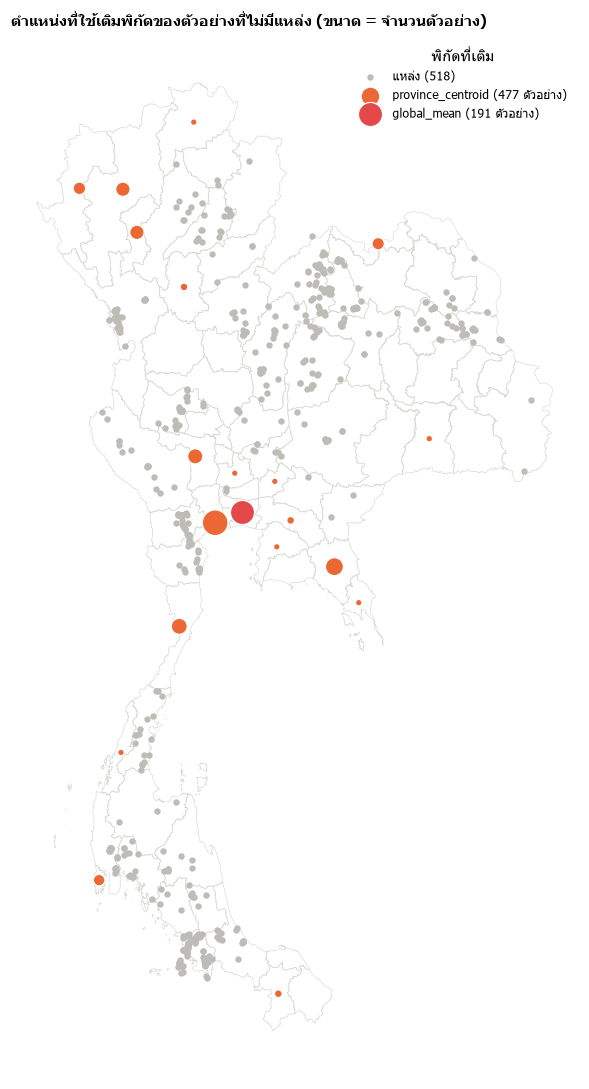

In [8]:
st = tables[("site", "impute_flag")]
fig, ax = plt.subplots(figsize=(7, 10))
gpd.read_file(DATA / "dmr_admin" / "provinces.geojson").boundary.plot(ax=ax, color="#d9d8d3", linewidth=0.4)
ax.scatter(st.geometry_x, st.geometry_y, s=10, color="#bdbcb6", label=f"แหล่ง ({len(st)})", zorder=2)
imp = sf[sf.coord_imputed.eq(1)].groupby(["geometry_x", "geometry_y", "coord_impute_level"]).size().reset_index(name="n")
for lvl, col in [("province_centroid", "#eb6834"), ("global_mean", "#e34948")]:
    sub = imp[imp.coord_impute_level.eq(lvl)]
    ax.scatter(sub.geometry_x, sub.geometry_y, s=np.sqrt(sub.n) * 18, color=col, edgecolor="white", linewidth=0.8, zorder=3,
               label=f"{lvl} ({sub.n.sum()} ตัวอย่าง)")
ax.set_axis_off()
ax.legend(loc="upper right", frameon=False, fontsize=8, title="พิกัดที่เติม")
ax.set_title("ตำแหน่งที่ใช้เติมพิกัดของตัวอย่างที่ไม่มีแหล่ง (ขนาด = จำนวนตัวอย่าง)", loc="left", fontweight="bold", fontsize=10)
plt.tight_layout()

ตัวอย่าง 191 ชิ้นที่ไม่รู้จังหวัด ได้ค่าเฉลี่ยทั้งประเทศซึ่งอยู่กลางประเทศ ไม่มีความหมายทางภูมิศาสตร์
แบบ Impute + Flag บอกโมเดลได้ว่าแถวนี้พิกัดไม่จริง (`coord_impute_level = global_mean`) แต่แบบ Impute Only โมเดลแยกไม่ออก

## 4. flag มีข้อมูลจริงไหม และข้อควรระวัง

ถ้าการขาดหายสัมพันธ์กับ target, flag จะช่วยโมเดลได้ แต่ถ้าสัมพันธ์กับ**การมี label** (แถวที่มี label มักไม่ขาด) จะเกิด **distribution shift**:
โมเดลเรียนจากแถวที่ feature ครบ แต่ต้องทำนายแถวที่ feature ขาด

มี label (train)  ไม่มี label (ต้องทำนาย)
ตาราง                            flag (% ที่ = 1)                                            
แหล่ง: target ยุค                formation_missing              15.7                     90.9
                                 geo_group_missing              19.9                     87.5
                                 has_locality                   70.5                     41.8
ตัวอย่าง: target ชื่อวิทยาศาสตร์ formation_missing              67.3                     77.7
                                 geo_group_missing              77.3                     79.7
                                 has_locality                   54.3                     22.1
                                 coord_imputed                   9.6                      5.6
                                 dis_name_missing               21.7                     40.7
                                 tambon_missing                 29.8                     25.8
                                 province_missing                2.5                      1.9

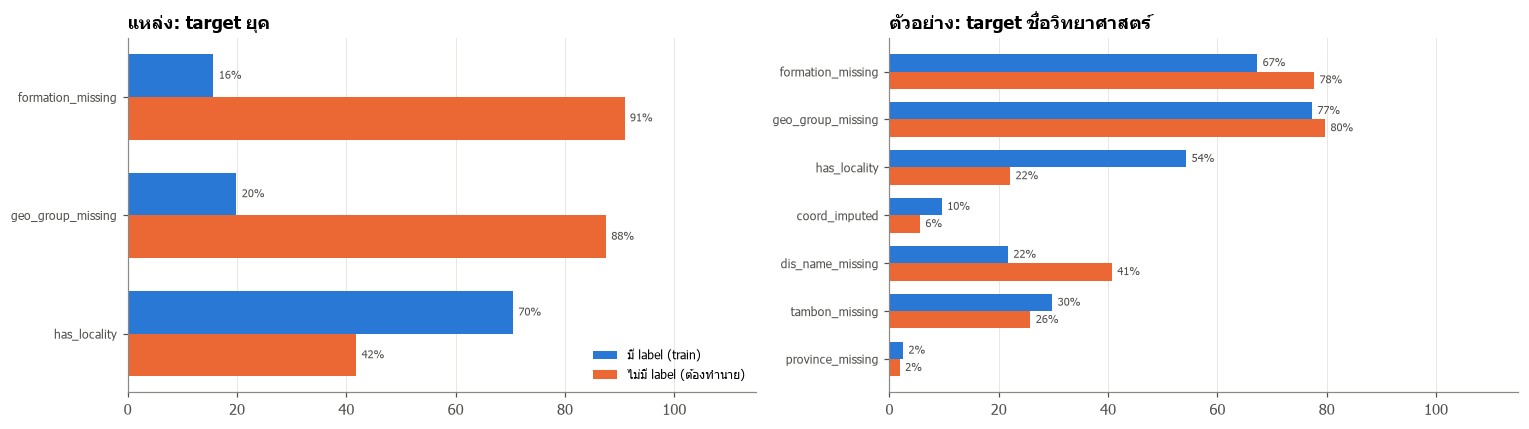

In [9]:
def shift_table(t, target, flags):
    lab = t[target].notna()
    return pd.DataFrame({
        "มี label (train)": t.loc[lab, flags].mean(),
        "ไม่มี label (ต้องทำนาย)": t.loc[~lab, flags].mean(),
    }).mul(100).round(1)


s_flags = ["formation_missing", "geo_group_missing", "has_locality"]
p_flags = ["formation_missing", "geo_group_missing", "has_locality", "coord_imputed", "dis_name_missing", "tambon_missing", "province_missing"]
st_shift = shift_table(tables[("site", "impute_flag")], "target_period", s_flags)
sp_shift = shift_table(tables[("spec", "impute_flag")], "target_sci_name", p_flags)
display(pd.concat({"แหล่ง: target ยุค": st_shift, "ตัวอย่าง: target ชื่อวิทยาศาสตร์": sp_shift}).rename_axis(["ตาราง", "flag (% ที่ = 1)"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (tbl, title) in zip(axes, [(st_shift, "แหล่ง: target ยุค"), (sp_shift, "ตัวอย่าง: target ชื่อวิทยาศาสตร์")]):
    y = np.arange(len(tbl))[::-1]
    ax.barh(y + 0.18, tbl.iloc[:, 0], height=0.36, color="#2a78d6", label="มี label (train)")
    ax.barh(y - 0.18, tbl.iloc[:, 1], height=0.36, color="#eb6834", label="ไม่มี label (ต้องทำนาย)")
    for yi, (a, b) in zip(y, tbl.values):
        ax.text(a + 1, yi + 0.18, f"{a:.0f}%", va="center", fontsize=7.5, color=INK)
        ax.text(b + 1, yi - 0.18, f"{b:.0f}%", va="center", fontsize=7.5, color=INK)
    ax.set_yticks(y, tbl.index, fontsize=8)
    ax.set_xlim(0, 115)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()

**ระดับแหล่ง (ยุค)**: แหล่งที่มียุคเกือบทั้งหมดมี `FORMATION` แต่แหล่งที่ต้องทำนายยุคแทบไม่มี `FORMATION` เลย
(ขาดพร้อมกันตามที่เห็นใน notebook 06) โมเดลที่เรียนรู้ว่า "หมวดหิน X → ยุค Y" จะใช้ความรู้นั้นกับแหล่งที่ต้องทำนายไม่ได้
ต้องพึ่งพิกัด จังหวัด และกลุ่มซากแทน ส่วนที่ 5 จึงแยกวัดความแม่นเฉพาะแถว test ที่ไม่มี `FORMATION` ไว้ด้วย

**ระดับตัวอย่าง (ชื่อวิทยาศาสตร์)**: shift น้อยกว่ามาก ยกเว้น `has_locality` และ `dis_name_missing`

## 5. ทดสอบเร็ว: flag ช่วยโมเดลไหม

ใช้ `RandomForestClassifier` (ไม่ได้ปรับจูน) กับ feature เดียวกัน ต่างกันแค่มี/ไม่มี flag
- **ยุค (แหล่ง)**: RepeatedKFold 5×3 บน 166 แหล่งที่มียุค และแยกความแม่นตาม `formation_missing` ของแถว test
- **ชื่อวิทยาศาสตร์ (ตัวอย่าง)**: 5-fold แบบสุ่ม (มองโลกในแง่ดี: แถวเหมือนกันทุกคอลัมน์อาจอยู่ทั้ง train/test)
  และ GroupKFold ตามแหล่ง (เข้มงวด: ทำนายแหล่งที่ไม่เคยเห็น)

การทดสอบนี้ใช้ค่าพิกัดที่ fit จากข้อมูลทั้งหมด ซึ่งไม่รั่วข้อมูล target เพราะพิกัดแหล่งมีครบและไม่เกี่ยวกับ label

In [10]:
FEATURES = {
    "site": {"cat": ["PROVINCE", "FORMATION", "GEO_GROUP", "IMPORTA_TH"],
             "num": COORDS + list(GR.values()) + ["n_specimens_linked"],
             "flag_num": ["formation_missing", "geo_group_missing", "has_locality", "coord_imputed"],
             "flag_cat": ["coord_impute_level"]},
    "spec": {"cat": ["com_name", "f_type", "f_group", "f_part", "dis_name", "province", "district", "tambon",
                     "match_level", "merge_confidence", "FORMATION", "GEO_GROUP"],
             "num": COORDS,
             "flag_num": ["formation_missing", "geo_group_missing", "has_locality", "coord_imputed", "com_name_missing",
                          "f_type_missing", "f_part_missing", "dis_name_missing", "district_missing", "tambon_missing", "province_missing"],
             "flag_cat": ["coord_impute_level"]},
}
TEXT = {"site": ["LOCALITY", "DISTRICT", "TAMBON"], "spec": ["LOCALITY"]}  # เก็บไว้ในตาราง แต่ไม่ใส่ในโมเดลทดสอบ


def feature_lists(level, version, df):
    f = FEATURES[level]
    cat, num = list(f["cat"]), list(f["num"])
    if version == "impute_flag":
        num += [c for c in f["flag_num"] if c in df.columns]
        cat += [c for c in f["flag_cat"] if c in df.columns]
    return cat, num


def make_model(cat, num, seed=0):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
                             ("num", "passthrough", num)])
    return Pipeline([("pre", pre), ("rf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=seed))])


def cv_eval(df, target, level, version, splitter, groups=None, seed=0):
    lab = df[df[target].notna()].reset_index(drop=True)
    cat, num = feature_lists(level, version, df)
    X, y = lab[cat + num], lab[target].astype(str)
    preds = []
    for k, (tr, te) in enumerate(splitter.split(X, y, groups if groups is None else groups(lab))):
        m = make_model(cat, num, seed).fit(X.iloc[tr], y.iloc[tr])
        preds.append(pd.DataFrame({"row": te, "fold": k, "correct": m.predict(X.iloc[te]) == y.iloc[te].values}))
    p = pd.concat(preds)
    return p.merge(lab.reset_index().rename(columns={"index": "row"}), on="row")


# รันหลาย seed (ทั้งการสุ่มแบ่ง fold และ random forest) เพื่อแยกผลของ flag ออกจากความผันผวนของการสุ่ม
SEEDS = [0, 1, 2, 3, 4]
results, by_formation = [], []
for seed in SEEDS:
    for version in ["impute_flag", "impute_only"]:
        t = tables[("site", version)]
        p = cv_eval(t, "target_period", "site", version, RepeatedKFold(n_splits=5, n_repeats=3, random_state=seed), seed=seed)
        results.append({"task": "ยุค (แหล่ง, 166)", "cv": "RepeatedKFold 5×3", "version": version, "seed": seed, "accuracy": p.correct.mean()})
        fm = tables[("site", "impute_flag")].set_index("OBJECTID").formation_missing
        by_formation.append(p.assign(formation_missing=p.OBJECTID.map(fm), version=version))

        t = tables[("spec", version)]
        for cv_name, splitter, groups in [
            ("5-fold สุ่ม", KFold(5, shuffle=True, random_state=seed), None),
            ("GroupKFold ตามแหล่ง", GroupKFold(5, shuffle=True, random_state=seed),
             lambda d: d.site_OBJECTID.astype("string").fillna("prov:" + d.province.astype(str))),
        ]:
            p = cv_eval(t, "target_sci_name", "spec", version, splitter, groups, seed=seed)
            results.append({"task": f"ชื่อวิทยาศาสตร์ (ตัวอย่าง, {t.target_sci_name.notna().sum():,})", "cv": cv_name,
                            "version": version, "seed": seed, "accuracy": p.correct.mean()})

res = pd.DataFrame(results)
agg = res.groupby(["task", "cv", "version"]).accuracy.agg(["mean", "min", "max"]).unstack("version")
diff = res.pivot_table(index=["task", "cv", "seed"], columns="version", values="accuracy")
diff = (diff.impute_flag - diff.impute_only).groupby(["task", "cv"]).agg(["mean", "min", "max"])
res_w = pd.DataFrame({
    "Impute + Missing Flag": agg[("mean", "impute_flag")], "Impute Only": agg[("mean", "impute_only")],
    "ต่างเฉลี่ย (Flag − Only)": diff["mean"], "ต่างต่ำสุด": diff["min"], "ต่างสูงสุด": diff["max"],
    "ช่วงของ Impute Only (max − min)": agg[("max", "impute_only")] - agg[("min", "impute_only")],
})
print(f"เฉลี่ยจาก {len(SEEDS)} seed")
display(res_w.style.format("{:.1%}").format("{:+.1%}", subset=["ต่างเฉลี่ย (Flag − Only)", "ต่างต่ำสุด", "ต่างสูงสุด"]))

bf = pd.concat(by_formation).groupby(["version", "formation_missing"]).correct.agg(["size", "mean"]).unstack(0)
print("ยุค (แหล่ง): ความแม่นแยกตามว่าแถว test มี FORMATION ไหม (n = จำนวนการทำนายรวมทุกรอบทุก seed)")
bf.style.format("{:.0%}", subset=[c for c in bf.columns if c[0] == "mean"])

เฉลี่ยจาก 5 seed


ยุค (แหล่ง): ความแม่นแยกตามว่าแถว test มี FORMATION ไหม (n = จำนวนการทำนายรวมทุกรอบทุก seed)


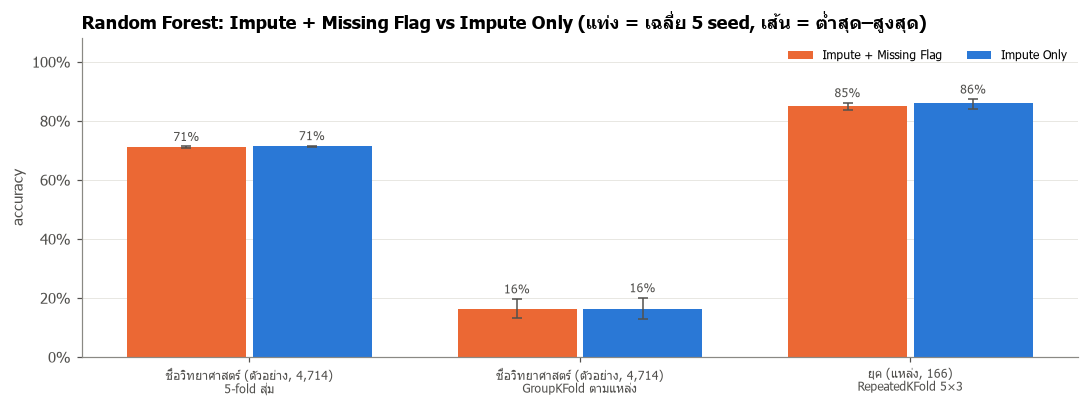

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = [f"{t}\n{c}" for t, c in res_w.index]
x = np.arange(len(res_w))
for i, v in enumerate(["impute_flag", "impute_only"]):
    mean_, lo, hi = agg[("mean", v)].values, agg[("min", v)].values, agg[("max", v)].values
    xs = x + (i - 0.5) * 0.38
    ax.bar(xs, mean_, width=0.36, color=VERSION_COLOR[v], label=VERSION_NAME[v])
    ax.errorbar(xs, mean_, yerr=[mean_ - lo, hi - mean_], fmt="none", ecolor=INK, elinewidth=1, capsize=3)
    for xi, val, h in zip(xs, mean_, hi):
        ax.text(xi, h + 0.01, f"{val:.0%}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("accuracy")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2)
ax.set_title(f"Random Forest: Impute + Missing Flag vs Impute Only (แท่ง = เฉลี่ย {len(SEEDS)} seed, เส้น = ต่ำสุด–สูงสุด)")
plt.tight_layout()

### ผลการทดสอบ (เฉลี่ย 5 seed)

**1. flag ไม่ช่วย Random Forest**
- ชื่อวิทยาศาสตร์: ต่างกันเฉลี่ย −0.3 จุด (แบ่งสุ่ม) และ +0.1 จุด (แบ่งตามแหล่ง) ซึ่งเล็กกว่าความผันผวนระหว่าง seed มาก (แบ่งตามแหล่งแกว่งถึง ~7 จุด)
- ยุค: แบบมี flag **ต่ำกว่าเล็กน้อยแต่สม่ำเสมอ** (−0.9 จุด ติดลบทุก seed)

**ทำไม**: flag ในตารางนี้แทบไม่มีข้อมูลใหม่
- `formation_missing = 1` เท่ากับ `FORMATION == 'Unknown'` ทุกแถว และ `has_locality` เท่ากับ `LOCALITY != ''`
  โมเดลต้นไม้แยกค่า `'Unknown'` เป็นกิ่งเองได้อยู่แล้ว (การ one-hot ก็ได้คอลัมน์ `Unknown` แยกเหมือนกัน)
- flag ที่ซ้ำกับข้อมูลเดิมไปเจือจางการสุ่มเลือก feature ของ Random Forest จึงแย่ลงเล็กน้อยในตารางแหล่งที่มี feature น้อย
- flag ที่ให้ข้อมูลใหม่จริงมีแค่ `coord_imputed` / `coord_impute_level` เพราะพิกัดที่เติมดูเหมือนพิกัดจริง
  แต่มีผลกับ 668 ตัวอย่าง (7.8%) ซึ่งส่วนใหญ่ไม่มี label จึงแทบไม่ได้ใช้ตอน train

**2. ชื่อวิทยาศาสตร์: ผลขึ้นกับว่าทำนายตัวอย่างในแหล่งที่เคยเห็นหรือไม่**
- แบ่งแบบสุ่ม ~71% แต่แบ่งตามแหล่ง ~16% ความแม่นส่วนใหญ่มาจาก "แหล่งนี้มักพบชนิดนี้"
- ตัวอย่างที่ต้องทำนาย **86% อยู่ในแหล่งที่มีตัวอย่างระบุชื่อแล้ว** ตัวเลขแบบสุ่มจึงใกล้งานจริงสำหรับกลุ่มนี้
  แต่ต้องระวัง: ตัวอย่าง `N/A (Dinosaur)` อาจเป็นคนละชนิดกับที่ระบุแล้วในแหล่งเดียวกัน คำทายจึงเป็น "ชนิดที่น่าจะเป็นตามแหล่ง" ไม่ใช่การจำแนกจริง
- อีก 14% (แหล่งใหม่หรือไม่มีแหล่ง) ใกล้กับตัวเลขแบบแบ่งตามแหล่งมากกว่า (~16%)

**3. ยุค: ~85–86%** บน 166 แหล่ง แถวที่ไม่มี `FORMATION` ได้ ~87–88% แต่มีแค่ 26 แหล่ง และ 18 แหล่งเป็นเพอร์เมียน (ยุคที่พบบ่อยสุด)
ตัวเลขนี้สูงเพราะคลาสไม่สมดุลมากกว่าเพราะโมเดลเก่ง แหล่งที่ต้องทำนายจริงกระจายในหลายจังหวัด (สตูล เลย ตาก เพชรบูรณ์ อุทัยธานี) ควรวัดผลเพิ่มแบบแยกตามจังหวัด

### ข้อแนะนำ
- **โมเดลต้นไม้ (Random Forest, Gradient Boosting) หรือ one-hot encoding: ใช้ Impute Only** ได้ผลเท่ากันหรือดีกว่าเล็กน้อย และ feature น้อยกว่า
- **ถ้าอยากเก็บข้อมูลว่าพิกัดถูกเติม** ให้ใช้ Impute Only แล้วเพิ่มเฉพาะ `coord_impute_level` (flag เดียวที่ไม่ซ้ำกับข้อมูลเดิม)
- **ไฟล์ Impute + Missing Flag** ยังมีประโยชน์ตอนวิเคราะห์และกรองคำทาย เช่น ไม่เชื่อคำทายของแถวที่ `coord_impute_level = global_mean`
  หรือใช้กับวิธี encode ที่แยก `'Unknown'` ไม่ได้ (เช่น target encoding)

## 6. บันทึกผล

`data/processed/model/`
| ไฟล์ | แถว | ใช้กับโมเดล |
|---|---|---|
| `sites_impute_flag.csv`, `sites_impute_only.csv` | 518 แหล่ง | ทำนายยุค (`target_period`) |
| `specimens_impute_flag.csv`, `specimens_impute_only.csv` | 8,521 ตัวอย่าง | ทำนายชื่อวิทยาศาสตร์ (`target_sci_name` / `target_genus`) และยุค |
| `feature_spec.json` | – | รายชื่อคอลัมน์ id / feature (หมวดหมู่, ตัวเลข, flag) / target / ref ของแต่ละตาราง |

**วิธีใช้**: แถวที่ target ไม่ว่างคือข้อมูล train แถวที่ target ว่างคือแถวที่ต้องทำนาย
**ห้ามใช้คอลัมน์ `ref_*` เป็น feature** (เป็นผลที่ได้จากการทายใน notebook 03–05 หรือเป็นรูปแบบอื่นของ target)
และอ่านไฟล์ด้วย `dtype={"fossil_id": str, "SITE_CODE": str}` เพื่อไม่ให้รหัสเสีย 0 นำหน้า

In [12]:
spec_json = {}
for (level, version), t in tables.items():
    name = {"site": "sites", "spec": "specimens"}[level]
    path = MODEL_DIR / f"{name}_{version}.csv"
    t.to_csv(path, index=False, encoding="utf-8-sig")
    cat, num = feature_lists(level, version, t)
    spec_json[f"{name}_{version}"] = {
        "file": path.name, "rows": len(t), "id": IDS[level], "target": TARGETS[level], "ref_do_not_use_as_feature": REFS[level],
        "features_categorical": cat, "features_numeric": num, "text_unused": TEXT[level],
        "flags": [c for c in num + cat if c.endswith("_missing") or c in ("has_locality", "coord_imputed", "coord_impute_level")],
    }
    print(f"บันทึก {path.name}: {t.shape}")
(MODEL_DIR / "feature_spec.json").write_text(json.dumps(spec_json, ensure_ascii=False, indent=2), encoding="utf-8")
print("บันทึก feature_spec.json")
pd.DataFrame({k: {"rows": v["rows"], "categorical": len(v["features_categorical"]), "numeric": len(v["features_numeric"]),
                  "flags": len(v["flags"]), "targets": ", ".join(v["target"])} for k, v in spec_json.items()}).T

บันทึก sites_impute_flag.csv: (518, 31)


บันทึก specimens_impute_flag.csv: (8521, 37)
บันทึก sites_impute_only.csv: (518, 26)
บันทึก specimens_impute_only.csv: (8521, 25)
บันทึก feature_spec.json


,rows,categorical,numeric,flags,targets
sites_impute_flag,518,5,14,5,"target_period, target_period_young"
specimens_impute_flag,8521,13,15,12,"target_sci_name, target_genus, target_period"
sites_impute_only,518,4,10,0,"target_period, target_period_young"
specimens_impute_only,8521,12,4,0,"target_sci_name, target_genus, target_period"


## 7. ข้อแนะนำสำหรับขั้นทำโมเดล

- **แบ่ง train/test ตามแหล่ง** (GroupKFold) สำหรับชื่อวิทยาศาสตร์ เพราะตัวอย่างจากแหล่งเดียวกันมักเหมือนกันทุกคอลัมน์ การแบ่งแบบสุ่มให้ตัวเลขสูงเกินจริง
- **ระวัง distribution shift ของยุค**: แหล่งที่ต้องทำนายแทบไม่มี `FORMATION` ให้วัดผลแยกเฉพาะแถว test ที่ `formation_missing = 1` (ส่วนที่ 5) ซึ่งใกล้งานจริงกว่า
- **ชื่อวิทยาศาสตร์มีหลายร้อยคลาส** ลองทำนายระดับสกุล (`target_genus`) หรือจำกัดเฉพาะคลาสที่มีตัวอย่างพอ แล้วรวมที่เหลือเป็น "อื่น ๆ"
- **fit ตัวแทนค่าใน train fold**: ถ้าใช้ค่าสถิติที่ขึ้นกับข้อมูล (เช่น ค่าเฉลี่ยจังหวัด) ให้เรียก `fit_impute` บน train แล้ว `impute` ทั้งสองชุด
- **ข้อความอิสระ** (`LOCALITY`, `FOS_DES_TH`) ยังไม่ได้แปลงเป็น feature ถ้าจะใช้ ต้องทำ text features แยก